# Regression Diagnostics: Outliers and Model Selection


## Correlated Predictors and Regression Estimates

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Small sample: b_reduced = 4.1679, b_full = 2.8155
Large sample: b_reduced = 4.4282, b_full = 2.9880
 SampleSize  Mean_b_full  Mean_b_reduced  Mean_Bias
         50     3.002181        4.408689   1.408689
        100     2.989185        4.396147   1.396147
        500     2.998664        4.396085   1.396085
       1000     2.999237        4.401352   1.401352
       2000     3.000527        4.403324   1.403324
 rho  Mean_Bias  Theoretical_Bias
 0.0  -0.013231               0.0
 0.2   0.416331               0.4
 0.4   0.803111               0.8
 0.6   1.199553               1.2
 0.8   1.605842               1.6
 0.9   1.794392               1.8


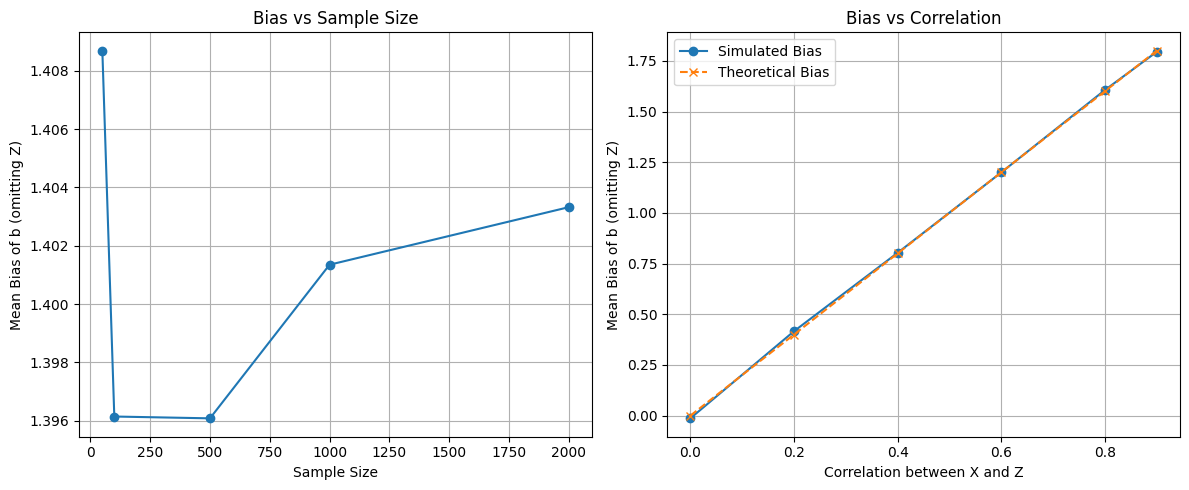

In [ ]:
def generate_XZ(n, rho, rng):
    X = rng.normal(0, 1, n)
    U = rng.normal(0, 1, n)
    Z = rho * X + np.sqrt(max(0.0, 1 - rho**2)) * U
    return X, Z

def ols_estimate(X_design, Y):
    beta_hat, residuals, rank, s = np.linalg.lstsq(X_design, Y, rcond=None)
    n, k = X_design.shape
    if residuals.size == 0:
        residuals_vec = Y - X_design @ beta_hat
        ss_res = np.sum(residuals_vec**2)
    else:
        ss_res = residuals[0]
    sigma2_hat = ss_res / (n - k)
    cov_beta = sigma2_hat * np.linalg.pinv(X_design.T @ X_design)
    se_beta = np.sqrt(np.diag(cov_beta))
    return beta_hat, se_beta, sigma2_hat

def run_single_simulation(n, a, b, c, rho, seed=42):
    rng = np.random.default_rng(seed)
    X, Z = generate_XZ(n, rho, rng)
    epsilon = rng.normal(0, 1, n)
    Y = a + b*X + c*Z + epsilon
    X_full = np.column_stack([np.ones(n), X, Z])
    beta_full, se_full, sigma2_full = ols_estimate(X_full, Y)
    X_red = np.column_stack([np.ones(n), X])
    beta_red, se_red, sigma2_red = ols_estimate(X_red, Y)
    return beta_full, beta_red

def monte_carlo_simulation(n_sim, sample_sizes, a, b, c, rho, seed=12345):
    rng_master = np.random.default_rng(seed)
    results = []
    for n in sample_sizes:
        b_full_list = []
        b_red_list = []
        for i in range(n_sim):
            sim_seed = int(rng_master.integers(0, 2**31 - 1))
            beta_full, beta_red = run_single_simulation(n, a, b, c, rho, seed=sim_seed)
            b_full_list.append(beta_full[1])
            b_red_list.append(beta_red[1])
        bias_array = np.array(b_red_list) - b
        results.append({
            'SampleSize': n,
            'Mean_b_full': np.mean(b_full_list),
            'Mean_b_reduced': np.mean(b_red_list),
            'Mean_Bias': np.mean(bias_array)
        })
    return pd.DataFrame(results)

def correlation_effect(n, correlations, a, b, c, n_sim=200, seed=2025):
    rng_master = np.random.default_rng(seed)
    results = []
    for rho in correlations:
        bias_vals = []
        for i in range(n_sim):
            sim_seed = int(rng_master.integers(0, 2**31 - 1))
            beta_full, beta_red = run_single_simulation(n, a, b, c, rho, seed=sim_seed)
            bias_vals.append(beta_red[1] - b)
        results.append({
            'rho': rho,
            'Mean_Bias': np.mean(bias_vals),
            'Theoretical_Bias': c * rho
        })
    return pd.DataFrame(results)

if __name__ == "__main__":
    TRUE_A, TRUE_B, TRUE_C = 5.0, 3.0, 2.0
    CORR_XZ = 0.7

    small = run_single_simulation(50, TRUE_A, TRUE_B, TRUE_C, CORR_XZ, seed=1)
    large = run_single_simulation(1000, TRUE_A, TRUE_B, TRUE_C, CORR_XZ, seed=2)
    print(f"Small sample: b_reduced = {small[1][1]:.4f}, b_full = {small[0][1]:.4f}")
    print(f"Large sample: b_reduced = {large[1][1]:.4f}, b_full = {large[0][1]:.4f}")

    sample_sizes = [50, 100, 500, 1000, 2000]
    mc_results = monte_carlo_simulation(500, sample_sizes, TRUE_A, TRUE_B, TRUE_C, CORR_XZ)
    print(mc_results.to_string(index=False))

    correlations = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9]
    corr_results = correlation_effect(500, correlations, TRUE_A, TRUE_B, TRUE_C)
    print(corr_results.to_string(index=False))

    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(mc_results['SampleSize'], mc_results['Mean_Bias'], marker='o')
    plt.xlabel('Sample Size')
    plt.ylabel('Mean Bias of b (omitting Z)')
    plt.title('Bias vs Sample Size')
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(corr_results['rho'], corr_results['Mean_Bias'], marker='o', label='Simulated Bias')
    plt.plot(corr_results['rho'], corr_results['Theoretical_Bias'], marker='x', linestyle='--', label='Theoretical Bias')
    plt.xlabel('Correlation between X and Z')
    plt.ylabel('Mean Bias of b (omitting Z)')
    plt.title('Bias vs Correlation')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## Regression Sensitivity to Outliers

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from scipy import stats

In [ ]:
# Set seed for reproducibility
np.random.seed(42)



## Generate clean data


In [ ]:
n = 100
X = np.random.normal(0, 1, n)
true_intercept, true_slope = 2, 3
y_clean = true_intercept + true_slope * X + np.random.normal(0, 1, n)

# 2. Introduce outliers
contamination = 0.05
n_outliers = int(n * contamination)
outlier_indices = np.random.choice(n, n_outliers, replace=False)

# Create contaminated dataset
X_contaminated = X.copy()
y_contaminated = y_clean.copy()
y_contaminated[outlier_indices] = true_intercept + true_slope * X[outlier_indices] + np.random.normal(15, 3, n_outliers)


## Fit regression models


In [ ]:
# Add constant for intercept
X_with_const = sm.add_constant(X)

# Clean data model
model_clean = sm.OLS(y_clean, X_with_const).fit()
clean_params = model_clean.params
clean_r2 = model_clean.rsquared
clean_std_err = model_clean.bse

# Contaminated data model
X_contaminated_const = sm.add_constant(X_contaminated)
model_contaminated = sm.OLS(y_contaminated, X_contaminated_const).fit()
contaminated_params = model_contaminated.params
contaminated_r2 = model_contaminated.rsquared
contaminated_std_err = model_contaminated.bse


## Create results table


In [ ]:
results = pd.DataFrame({
    'Parameter': ['Intercept', 'Slope', 'R²'],
    'True Value': [true_intercept, true_slope, 'N/A'],
    'Clean Estimate': [f"{clean_params[0]:.4f} (±{clean_std_err[0]:.4f})",
                       f"{clean_params[1]:.4f} (±{clean_std_err[1]:.4f})",
                       f"{clean_r2:.4f}"],
    'Contaminated Estimate': [f"{contaminated_params[0]:.4f} (±{contaminated_std_err[0]:.4f})",
                              f"{contaminated_params[1]:.4f} (±{contaminated_std_err[1]:.4f})",
                              f"{contaminated_r2:.4f}"],
    'Change (%)': [
        f"{((contaminated_params[0] - clean_params[0]) / clean_params[0]) * 100:.1f}%",
        f"{((contaminated_params[1] - clean_params[1]) / clean_params[1]) * 100:.1f}%",
        f"{((contaminated_r2 - clean_r2) / clean_r2) * 100:.1f}%"
    ]
})

print("=" * 80)
print("REGRESSION PARAMETER COMPARISON: CLEAN vs CONTAMINATED DATA")
print("=" * 80)
print(results.to_string(index=False))
print("\n")

# 5. Diagnostic metrics
print("ADDITIONAL DIAGNOSTICS:")
print("-" * 40)
print(f"Number of outliers introduced: {n_outliers} ({contamination*100}% of data)")
print(f"Mean Squared Error (Clean): {np.mean((y_clean - model_clean.predict(X_with_const))**2):.4f}")
print(f"Mean Squared Error (Contaminated): {np.mean((y_contaminated - model_contaminated.predict(X_contaminated_const))**2):.4f}")
print("\n")


## Create visualizations


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: Clean data with regression line
axes[0, 0].scatter(X, y_clean, alpha=0.7, label='Data points')
x_range = np.linspace(X.min(), X.max(), 100)
y_clean_pred = clean_params[0] + clean_params[1] * x_range
axes[0, 0].plot(x_range, y_clean_pred, 'r-', linewidth=2, label=f'Fit: y = {clean_params[0]:.2f} + {clean_params[1]:.2f}x')
axes[0, 0].plot(x_range, true_intercept + true_slope * x_range, 'g--', linewidth=2, label=f'True: y = {true_intercept} + {true_slope}x')
axes[0, 0].set_xlabel('X')
axes[0, 0].set_ylabel('Y')
axes[0, 0].set_title('Clean Data (No Outliers)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Contaminated data with regression line
axes[0, 1].scatter(X_contaminated, y_contaminated, alpha=0.7, label='Data points')
# Mark outliers
axes[0, 1].scatter(X_contaminated[outlier_indices], y_contaminated[outlier_indices],
                   color='red', s=100, alpha=0.7, label='Outliers', edgecolors='black', linewidth=1.5)
y_contaminated_pred = contaminated_params[0] + contaminated_params[1] * x_range
axes[0, 1].plot(x_range, y_contaminated_pred, 'r-', linewidth=2, label=f'Fit: y = {contaminated_params[0]:.2f} + {contaminated_params[1]:.2f}x')
axes[0, 1].plot(x_range, true_intercept + true_slope * x_range, 'g--', linewidth=2, label=f'True: y = {true_intercept} + {true_slope}x')
axes[0, 1].set_xlabel('X')
axes[0, 1].set_ylabel('Y')
axes[0, 1].set_title('Data with 5% Outliers')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Residuals comparison
residuals_clean = y_clean - model_clean.predict(X_with_const)
residuals_contaminated = y_contaminated - model_contaminated.predict(X_contaminated_const)

axes[1, 0].scatter(model_clean.predict(X_with_const), residuals_clean, alpha=0.7)
axes[1, 0].axhline(y=0, color='r', linestyle='--')
axes[1, 0].set_xlabel('Fitted Values')
axes[1, 0].set_ylabel('Residuals')
axes[1, 0].set_title('Residual Plot: Clean Data')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].scatter(model_contaminated.predict(X_contaminated_const), residuals_contaminated, alpha=0.7)
axes[1, 1].scatter(model_contaminated.predict(X_contaminated_const)[outlier_indices],
                   residuals_contaminated[outlier_indices], color='red', s=100, alpha=0.7, edgecolors='black', linewidth=1.5)
axes[1, 1].axhline(y=0, color='r', linestyle='--')
axes[1, 1].set_xlabel('Fitted Values')
axes[1, 1].set_ylabel('Residuals')
axes[1, 1].set_title('Residual Plot: Contaminated Data (Outliers in red)')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Show Cook's distance for outlier detection


REGRESSION PARAMETER COMPARISON: CLEAN vs CONTAMINATED DATA
Parameter True Value   Clean Estimate Contaminated Estimate Change (%)
Intercept          2 2.0074 (±0.0956)      2.7599 (±0.3441)      37.5%
    Slope          3 2.8567 (±0.1051)      2.7891 (±0.3783)      -2.4%
       R²        N/A           0.8829                0.3567     -59.6%


ADDITIONAL DIAGNOSTICS:
----------------------------------------
Number of outliers introduced: 5 (5.0% of data)
Mean Squared Error (Clean): 0.8836
Mean Squared Error (Contaminated): 11.4533




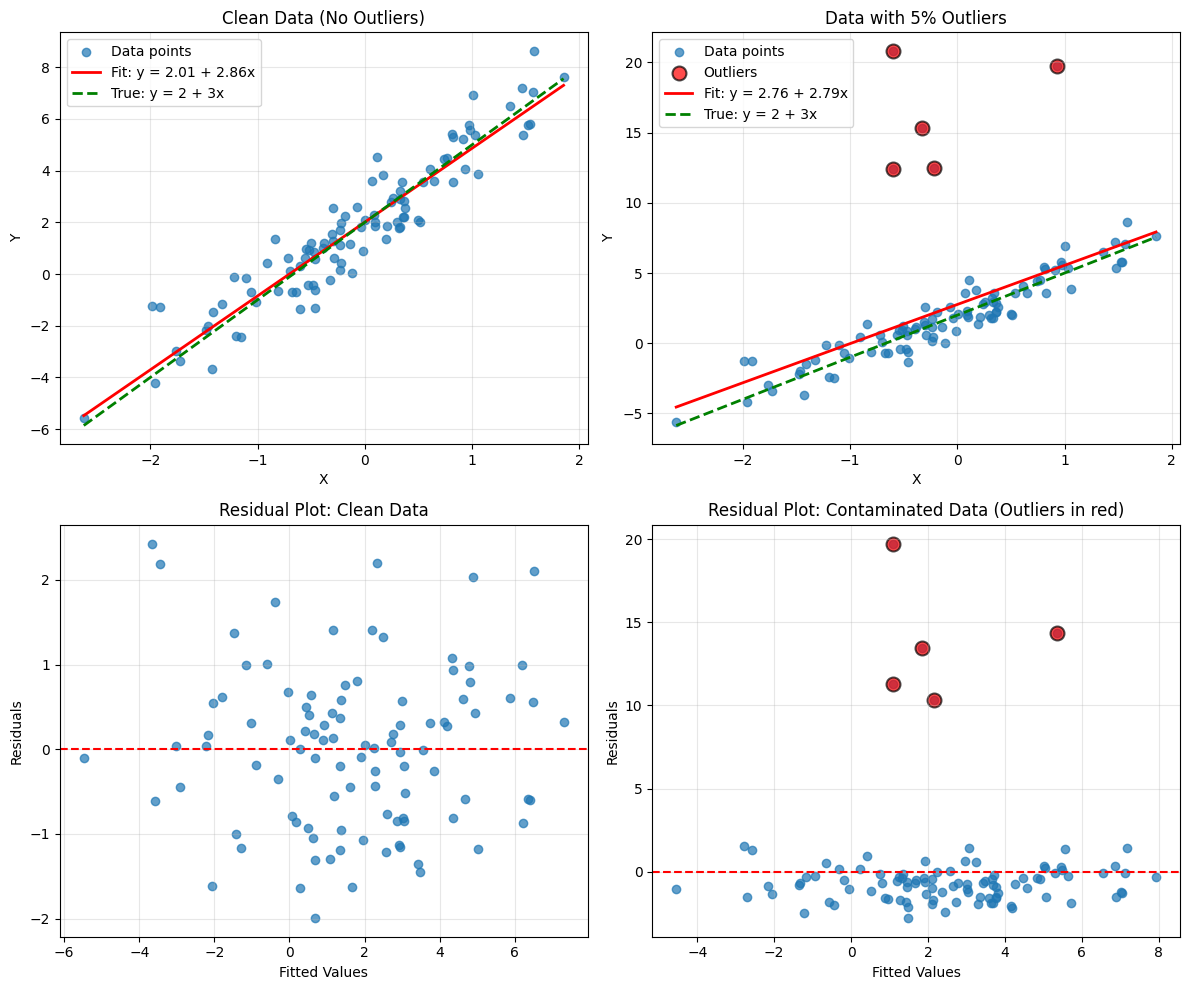

OUTLIER DETECTION METRICS:
----------------------------------------
Clean data - Influential points (Cook's distance > 0.040): 5
Contaminated data - Influential points (Cook's distance > 0.040): 5
Outliers correctly identified: 5/5

ROBUST REGRESSION COMPARISON:
----------------------------------------
Huber Robust Regression:
  Intercept: 2.0843 (vs OLS: 2.7599)
  Slope: 2.8578 (vs OLS: 2.7891)
  Closer to true values? Intercept: True
  Closer to true values? Slope: True


In [ ]:
print("OUTLIER DETECTION METRICS:")
print("-" * 40)
# Calculate Cook's distance manually
def cook_distance(model, X, y):
    n = len(y)
    p = X.shape[1]
    residuals = y - model.predict(X)
    leverage = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)
    mse = np.sum(residuals**2) / (n - p)
    return (residuals**2 * leverage) / (p * mse * (1 - leverage)**2)

cook_clean = cook_distance(model_clean, X_with_const, y_clean)
cook_contaminated = cook_distance(model_contaminated, X_contaminated_const, y_contaminated)

# Identify influential points (Cook's distance > 4/n)
influential_clean = np.where(cook_clean > 4/n)[0]
influential_contaminated = np.where(cook_contaminated > 4/n)[0]

print(f"Clean data - Influential points (Cook's distance > {4/n:.3f}): {len(influential_clean)}")
print(f"Contaminated data - Influential points (Cook's distance > {4/n:.3f}): {len(influential_contaminated)}")
print(f"Outliers correctly identified: {np.isin(outlier_indices, influential_contaminated).sum()}/{n_outliers}")

# 8. Demonstrate robust regression alternative
print("\nROBUST REGRESSION COMPARISON:")
print("-" * 40)
# Huber robust regression
huber_model = sm.RLM(y_contaminated, X_contaminated_const, M=sm.robust.norms.HuberT())
huber_results = huber_model.fit()
print(f"Huber Robust Regression:")
print(f"  Intercept: {huber_results.params[0]:.4f} (vs OLS: {contaminated_params[0]:.4f})")
print(f"  Slope: {huber_results.params[1]:.4f} (vs OLS: {contaminated_params[1]:.4f})")
print(f"  Closer to true values? Intercept: {abs(huber_results.params[0]-true_intercept) < abs(contaminated_params[0]-true_intercept)}")
print(f"  Closer to true values? Slope: {abs(huber_results.params[1]-true_slope) < abs(contaminated_params[1]-true_slope)}")


## Information-Criterion Model Selection

In [ ]:
import numpy, pandas, gdown, os, itertools
from sklearn.model_selection import train_test_split as data_split
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from tqdm.notebook import tqdm

In [ ]:
!pip install gdown

In [ ]:
gdown.download_folder(id = "18mP2Dn3tezwmHFLbS3od1n7MIGxg1MUA", output = "data", quiet = False, use_cookies = False)
files = os.listdir("data")

Retrieving folder contents


Processing file 1kSdBaTujbqbVrPz6spdD6PEWmgVm0Y3d FE-GWP1_model_selection_2.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1kSdBaTujbqbVrPz6spdD6PEWmgVm0Y3d
To: /content/data/FE-GWP1_model_selection_2.csv
100%|██████████| 7.58k/7.58k [00:00<00:00, 17.3MB/s]
Download completed


In [ ]:
dataframe = pandas.read_csv('data/financial_model_selection.csv')
dataframe.columns = [column.strip() for column in dataframe.columns]
dataframe = pandas.concat([dataframe.loc[:, ['Y']],
               pandas.DataFrame([1] * dataframe.shape[0], columns = ['Z0']),
               dataframe.iloc[:, 1:]], axis = 1)

def split_features_and_target(X, Y, split_ratio = 0.2):
    X_train, X_test, y_train, y_test = data_split(X, Y, test_size = split_ratio, random_state = 7)
    return pandas.concat([X_train, y_train], axis = 1).reset_index(drop = True), pandas.concat([X_test, y_test], axis = 1).reset_index(drop = True)

def split(frame):
    X = frame.iloc[:, :-1]
    Y = frame.iloc[:, -1]
    return X, Y

training, testing = split_features_and_target(dataframe.iloc[:, 1:], dataframe.iloc[:, 0], split_ratio = 0.2)
X, Y = split(training)
N, P = X.shape
P = P + 1
cv = KFold(n_splits = 5, shuffle = True, random_state = 7)
linear_model = LinearRegression()
full_model_variance = numpy.sum((Y - linear_model.fit(X, Y).predict(X))**2) / (N - P)
args = {'tol': 1e-20, 'max_iter': 50_000}

def cross_validation(X, Y):
    AIC  = []
    BIC  = []
    MCp   = []
    p = X.shape[1] + 1

    for train_idx, test_idx in cv.split(X):
        Xtr, Xte = X.iloc[train_idx, :], X.iloc[test_idx, :]
        Ytr, Yte = Y[train_idx], Y[test_idx]
        n = len(Yte)

        model = LinearRegression().fit(Xtr, Ytr)
        y = model.predict(Xte)
        MSE = numpy.sum((Yte - y)**2) / n

        # ------- AIC -------
        loglikelihood = n * ((numpy.log(2 * numpy.pi * MSE)) + 1) / -2
        AIC.append(2*p - 2*loglikelihood)

        # ------- BIC -------
        BIC.append(p * numpy.log(n) - 2*loglikelihood)

        # ------- Mallows' Cp -------
        MCp.append((MSE * n / full_model_variance) - (n - 2*p))

    return numpy.mean(AIC), numpy.mean(BIC), numpy.mean(MCp)

def forward_stepwise_regression(X, Y, criterion):
    remaining = list(X.columns)
    included = []
    best_score = numpy.inf

    while remaining:
        candidates = []
        for candidate in remaining:
            U = X.loc[:, included + [candidate]]
            aic, bic, cp = cross_validation(U, Y)
            candidates.append({'aic': aic, 'bic': bic, 'cp': cp, 'variable': candidate})

        print("Fitted: ", included)
        best_candidate = min(candidates, key = lambda x: x[criterion])
        print("Current score:", best_score)
        print(f"Best candidate: {best_candidate}\n")
        if best_candidate[criterion] < best_score:
            best_score = best_candidate[criterion]
            included.append(best_candidate['variable'])
            remaining.remove(best_candidate['variable'])

        else:
            break

    return {"included": included, "excluded": list(set(list(X.columns)) - set(included)), "criterion": criterion, "best score": best_score}

def backward_stepwise_regression(X, Y, criterion):
    remaining = list(X.columns)
    included = list(X.columns)
    best_score = numpy.inf

    while remaining:
        candidates = []
        for candidate in remaining:
            U = X.loc[:, list(set(included) - set([candidate]))]
            aic, bic, cp = cross_validation(U, Y)
            candidates.append({'aic': aic, 'bic': bic, 'cp': cp, 'variable': candidate})

        print("Fitted: ", included)
        best_candidate = min(candidates, key = lambda x: x[criterion])
        print("Current score:", best_score)
        print(f"Best candidate: {best_candidate}\n")
        if best_candidate[criterion] < best_score:
            best_score = best_candidate[criterion]
            included.remove(best_candidate['variable'])
            remaining.remove(best_candidate['variable'])

        else:
            break

    return {"included": included, "excluded": list(set(list(X.columns)) - set(included)), "criterion": criterion, "best score": best_score}

def get_min_items(items, key):
    min_value = min(item[key] for item in items)
    return [item for item in items if item[key] == min_value]

def all_subsets_stepwise_regression(X, Y, criterion):
    items = X.columns.tolist()

    combinations = []
    for r in range(len(items) + 1):
        for combo in itertools.combinations(items, r):
            if r > 0:
                combinations.append(list(combo))

    best_score = numpy.inf

    candidates = []
    for candidate in tqdm(combinations, desc = "Evaluating combinations", ncols = 800):
        U = X.loc[:, candidate]
        aic, bic, cp = cross_validation(U, Y)
        candidates.append({'aic': aic, 'bic': bic, 'cp': cp, 'variables': candidate})

    best_candidate = get_min_items(candidates, criterion)
    print("Current score:", best_score)
    print("Number of candidates:", len(best_candidate))
    print(f"Best candidate: {best_candidate}\n")
    if len(best_candidate):
        best_candidate = best_candidate[0]
        return {"included": best_candidate['variables'], "excluded": list(set(list(X.columns)) - set(best_candidate['variables'])),
                    "criterion": criterion, "best score": best_candidate[criterion]}

In [ ]:
forward_stepwise_regression(X, Y, 'bic')

Fitted:  []
Current score: inf
Best candidate: {'aic': np.float64(24.618080112704764), 'bic': np.float64(26.16325755718433), 'cp': np.float64(358.0282444543724), 'variable': 'Z4'}

Fitted:  ['Z4']
Current score: 26.16325755718433
Best candidate: {'aic': np.float64(5.962276097501743), 'bic': np.float64(8.280042264221086), 'cp': np.float64(93.88695284395968), 'variable': 'Z3'}

Fitted:  ['Z4', 'Z3']
Current score: 8.280042264221086
Best candidate: {'aic': np.float64(-5.856239440403652), 'bic': np.float64(-2.7658845514445267), 'cp': np.float64(33.56624458935595), 'variable': 'Z5'}

Fitted:  ['Z4', 'Z3', 'Z5']
Current score: -2.7658845514445267
Best candidate: {'aic': np.float64(-10.91513611587266), 'bic': np.float64(-7.052192504673752), 'cp': np.float64(20.85177567952178), 'variable': 'Z2'}

Fitted:  ['Z4', 'Z3', 'Z5', 'Z2']
Current score: -7.052192504673752
Best candidate: {'aic': np.float64(-16.948691812327446), 'bic': np.float64(-12.31315947888876), 'cp': np.float64(12.237914660094031)

{'included': ['Z4', 'Z3', 'Z5', 'Z2', 'Z1'],
 'excluded': ['Z0'],
 'criterion': 'bic',
 'best score': np.float64(-12.31315947888876)}

In [ ]:
backward_stepwise_regression(X, Y, 'bic')

Fitted:  ['Z0', 'Z1', 'Z2', 'Z3', 'Z4', 'Z5']
Current score: inf
Best candidate: {'aic': np.float64(-16.948691812327347), 'bic': np.float64(-12.313159478888664), 'cp': np.float64(12.237914660094134), 'variable': 'Z0'}

Fitted:  ['Z1', 'Z2', 'Z3', 'Z4', 'Z5']
Current score: -12.313159478888664
Best candidate: {'aic': np.float64(-10.915136115872668), 'bic': np.float64(-7.052192504673762), 'cp': np.float64(20.851775679521765), 'variable': 'Z1'}



{'included': ['Z1', 'Z2', 'Z3', 'Z4', 'Z5'],
 'excluded': ['Z0'],
 'criterion': 'bic',
 'best score': np.float64(-12.313159478888664)}

In [ ]:
all_subsets_stepwise_regression(X, Y, 'bic')

Evaluating combinations:   0%|                                                                                …

Current score: inf
Number of candidates: 1
Best candidate: [{'aic': np.float64(-16.94869181232747), 'bic': np.float64(-12.313159478888783), 'cp': np.float64(12.237914660094015), 'variables': ['Z1', 'Z2', 'Z3', 'Z4', 'Z5']}]



{'included': ['Z1', 'Z2', 'Z3', 'Z4', 'Z5'],
 'excluded': ['Z0'],
 'criterion': 'bic',
 'best score': np.float64(-12.313159478888783)}

## Stationarity Tests for Equity Prices

In [ ]:
import yfinance, matplotlib.pyplot as plot, warnings
from statsmodels.tsa.stattools import adfuller as HypothesisADF, kpss as HypothesisKPSS
warnings.filterwarnings("ignore")

In [ ]:
data = yfinance.download(['^IXIC'], start = '2000-01-01', end = "2025-12-11", auto_adjust = False)
asset_prices = data.copy(deep = True)
asset_prices.index = list((pandas.to_datetime(asset_prices.index) - pandas.Timedelta(days = 1)).strftime('%Y-%m-%d'))
asset_prices.columns = [' '.join(column).strip().replace('^IXIC', 'NASDAQ') for column in asset_prices.columns.values]
closing_prices = asset_prices.loc[:, asset_prices.columns.str.startswith('Adj')].dropna()

[*********************100%***********************]  1 of 1 completed


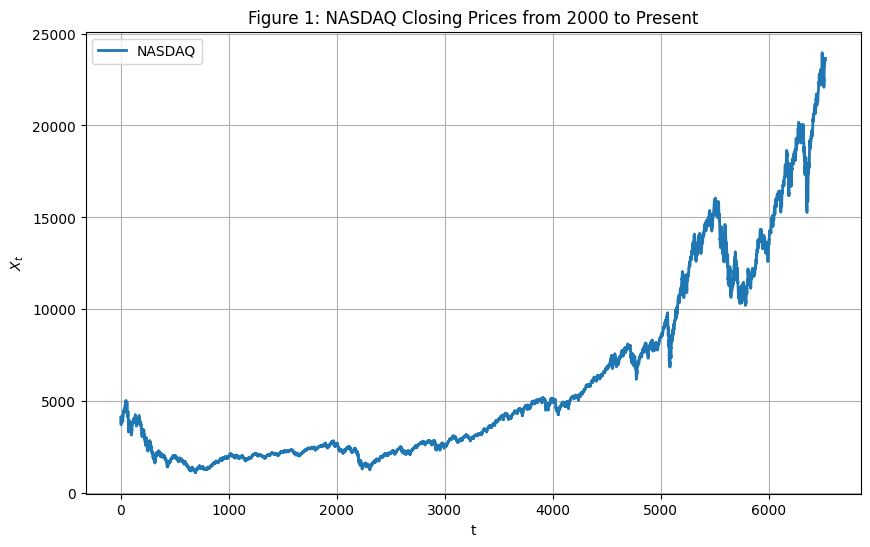

In [ ]:
def hypothesis_ADF(series):
    print("="*45)
    print("AUGMENTED DICKEY-FULLER TEST (ADF)")
    print("="*45)
    adf_result = HypothesisADF(series, autolag = 'AIC')
    print("Test: p < 0.05 → reject H₀ → stationary")
    print(f"ADF Statistic  : {adf_result[0]:.4f}")
    print(f"p-value        : {adf_result[1]:.4f}")
    print("Critical Values:")
    for key, value in adf_result[4].items():
        print(f"   {key:>4}: {value:.4f}")

def hypothesis_KPSS(series):
    print("="*45)
    print("\nKWIATKOWSKI-PHILLIPS-SCHMIDT-SHIN TEST (KPSS)")
    print("="*45)
    print("Test: p < 0.05 → reject H₀ → non-stationary")
    kpss_result = HypothesisKPSS(series, regression = 'c', nlags = 'auto')
    print(f"KPSS Statistic : {kpss_result[0]:.4f}")
    print(f"p-value        : {kpss_result[1]:.4f}")
    print("Critical Values:")
    for key, value in kpss_result[3].items():
        print(f"   {key:>}: {value:.4f}")

plot.figure(figsize = (10, 6))

plot.plot(closing_prices['Adj Close NASDAQ'].values, label = "NASDAQ", linewidth = 2)

plot.title("Figure 1: NASDAQ Closing Prices from 2000 to Present")
plot.xlabel("t")
plot.ylabel("$X_{t}$")
plot.legend()
plot.grid(True)
plot.show()

In [ ]:
hypothesis_ADF(closing_prices['Adj Close NASDAQ'])

AUGMENTED DICKEY-FULLER TEST (ADF)
Test: p < 0.05 → reject H₀ → stationary
ADF Statistic  : 2.9287
p-value        : 1.0000
Critical Values:
     1%: -3.4314
     5%: -2.8620
    10%: -2.5670


In [ ]:
hypothesis_KPSS(closing_prices['Adj Close NASDAQ'])


KWIATKOWSKI-PHILLIPS-SCHMIDT-SHIN TEST (KPSS)
Test: p < 0.05 → reject H₀ → non-stationary
KPSS Statistic : 9.7054
p-value        : 0.0100
Critical Values:
   10%: 0.3470
   5%: 0.4630
   2.5%: 0.5740
   1%: 0.7390


## Monte Carlo Time-Series Simulation

In [ ]:
def simulate(S0 = 1, mu = 0.08, sigma = 0.15, years = 10, steps = 252):
    numpy.random.seed(7)
    dt = years / steps

    S = [S0]
    for _ in range(steps):
        S.append(S[-1] * numpy.exp((mu - 0.5 * sigma**2) * dt + sigma * numpy.random.normal(0, numpy.sqrt(dt))))

    return numpy.array(S)

Yt = simulate()

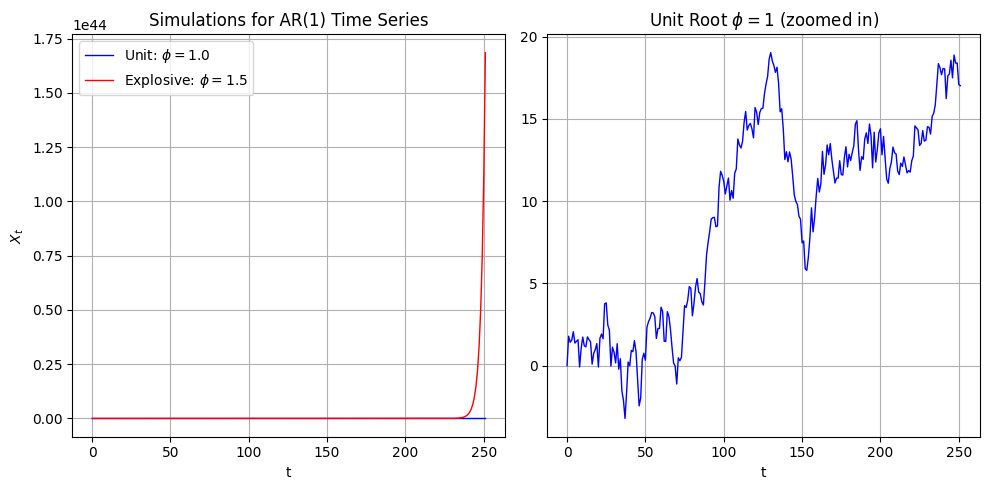

In [ ]:
def AR1(Φ, T = 252, µ = 0.1):
    numpy.random.seed(7)
    x = numpy.zeros(T)
    for t in range(1, T):
        x[t] = Φ * x[t - 1] + µ + numpy.random.normal(0, 1)

    return x

Yt = AR1(Φ = 1.0)
St = AR1(Φ = 1.5)
fig, axes = plot.subplots(1, 2, figsize = (10, 5))

axes[0].plot(Yt, label = "Unit: $\\phi=1.0$", linewidth = 1, color = 'blue')
axes[0].plot(St, label = "Explosive: $\\phi=1.5$", linewidth = 1, color = 'red')
axes[0].set_title("Simulations for AR(1) Time Series")
axes[0].set_ylabel("$X_{t}$")
axes[0].set_xlabel("t")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(Yt, color = 'blue', linewidth = 1)
axes[1].set_title("Unit Root $\\phi=1$ (zoomed in)")
axes[1].set_xlabel("t")
axes[1].grid(True)

plot.tight_layout()
plot.show()